# Tunable Coupler (MIT)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/qiskit-community/qiskit-metal/blob/main/docs/circuit-examples/D.Qubit-couplers/31-TwoCrossmonsTunableCoupler.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/qiskit-community/qiskit-metal/main?labpath=docs%2Fcircuit-examples%2FD.Qubit-couplers%2F31-TwoCrossmonsTunableCoupler.ipynb)

> 💡 **Running in Colab or Binder?** Skip the desktop GUI install — the cell below grabs the lite (no-Qt) wheel, and `qm.gui(design)` auto-picks an inline matplotlib viewer with the same API (`gui.rebuild()`, `gui.screenshot()`, `gui.edit_component(...)`) as the desktop `MetalGUI`.

In [1]:
import qiskit_metal as metal
from qiskit_metal import designs, MetalGUI

In [2]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
# !pip install -q quantum-metal

> 💡 **Using this tutorial without the Qt GUI**
> 
> This tutorial uses the desktop `MetalGUI`. To follow along on Colab, Binder, JupyterHub, or any environment where Qt isn't available, **replace any `gui.rebuild()` / `gui.screenshot()` call with `qm.view(design)`** — it renders the design to a matplotlib `Figure` you can display inline or save with `fig.savefig(...)`.
> 
> See [1.1 Quick start](https://qiskit-community.github.io/qiskit-metal/tut/1-Overview/1.1-Quick-start.html) for a complete runnable walkthrough and [`docs/headless-usage.rst`](https://qiskit-community.github.io/qiskit-metal/headless-usage.html) for the full reference.

### Create the design in Metal
Setup a design of a given dimension. Dimensions will be respected in the design rendering. <br>
The chip is centred on the origin: it spans ±size_x/2 and ±size_y/2.

In [3]:
design = designs.DesignPlanar({}, True)
design.chips.main.size["size_x"] = "3mm"
design.chips.main.size["size_y"] = "3mm"

gui = MetalGUI(design)

Create two crossmons coupled together with an interdigitated tunable coupler.

In [4]:
from qiskit_metal.qlibrary.qubits.transmon_cross_fl import TransmonCrossFL
from qiskit_metal.qlibrary.couplers.tunable_coupler_01 import TunableCoupler01

In [5]:
TransmonCrossFL.get_template_options(design)

{'pos_x': '0.0um',
 'pos_y': '0.0um',
 'orientation': '0.0',
 'chip': 'main',
 'layer': '1',
 'connection_pads': {},
 '_default_connection_pads': {'connector_type': '0',
  'claw_length': '30um',
  'ground_spacing': '5um',
  'ground_spacing_back': None,
  'claw_width': '10um',
  'claw_width_back': None,
  'claw_gap': '6um',
  'claw_cpw_length': '40um',
  'claw_cpw_width': '10um',
  'connector_location': '0'},
 'cross_width': '20um',
 'cross_length': '200um',
 'cross_gap': '20um',
 'make_fl': True,
 'fl_options': {'t_top': '15um',
  't_offset': '0um',
  't_inductive_gap': '3um',
  't_width': '5um',
  't_gap': '3um'},
 'gds_cell_name': 'my_other_junction'}

In [6]:
TunableCoupler01.get_template_options(design)

{'pos_x': '0.0um',
 'pos_y': '0.0um',
 'orientation': '0.0',
 'chip': 'main',
 'layer': '1',
 'connection_pads': {},
 '_default_connection_pads': {},
 'c_width': '400um',
 'l_width': '20um',
 'l_gap': '10um',
 'a_height': '60um',
 'cp_height': '15um',
 'cp_arm_length': '30um',
 'cp_arm_width': '6um',
 'cp_gap': '6um',
 'cp_gspace': '3um',
 'fl_width': '5um',
 'fl_gap': '3um',
 'fl_length': '10um',
 'fl_ground': '2um',
 'gds_cell_name': 'my_other_junction'}

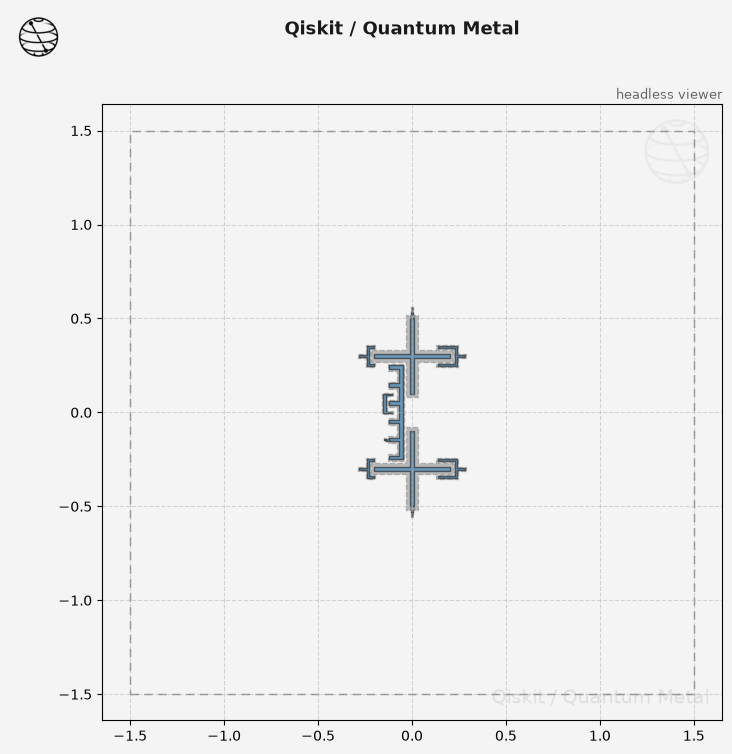

In [7]:
Q1 = TransmonCrossFL(
    design,
    "Q1",
    options=dict(
        pos_x="0",
        pos_y="-0.3mm",
        connection_pads=dict(
            bus_01=dict(connector_location="180", claw_length="95um"),
            readout=dict(connector_location="0"),
        ),
        fl_options=dict(),
    ),
)

Q2 = TransmonCrossFL(
    design,
    "Q2",
    options=dict(
        pos_x="0",
        pos_y="0.3mm",
        orientation="180",
        connection_pads=dict(
            bus_02=dict(connector_location="0", claw_length="95um"),
            readout=dict(connector_location="180"),
        ),
        fl_options=dict(),
    ),
)


tune_c_Q12 = TunableCoupler01(
    design,
    "Tune_C_Q12",
    options=dict(pos_x="-0.06mm", pos_y="0", orientation=90, c_width="500um"),
)

gui.rebuild()
gui.autoscale()

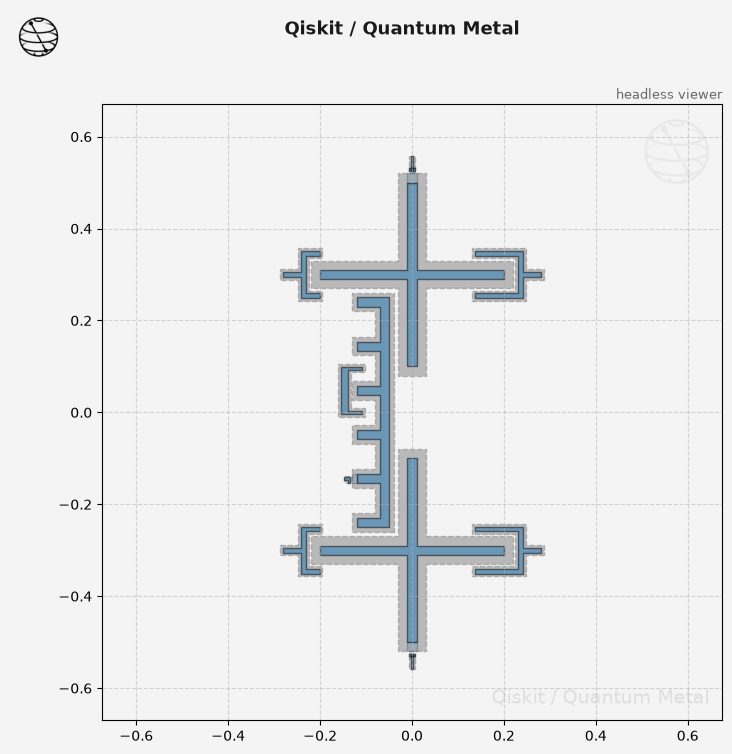

In [8]:
# Get a list of all the qcomponents in QDesign and then zoom on them.
all_component_names = design.components.keys()

gui.zoom_on_components(all_component_names)

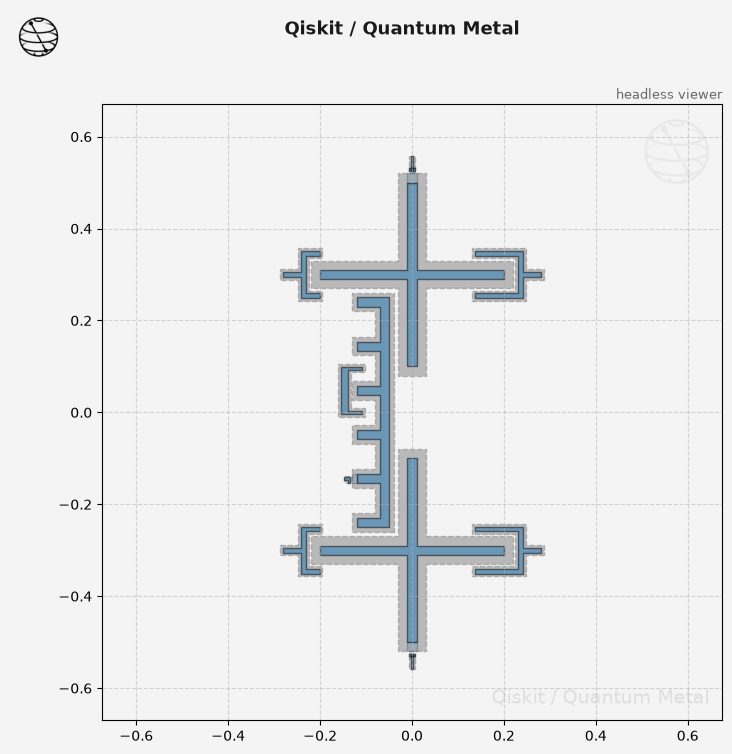

In [9]:
# Save screenshot as a .png formatted file.
gui.screenshot()

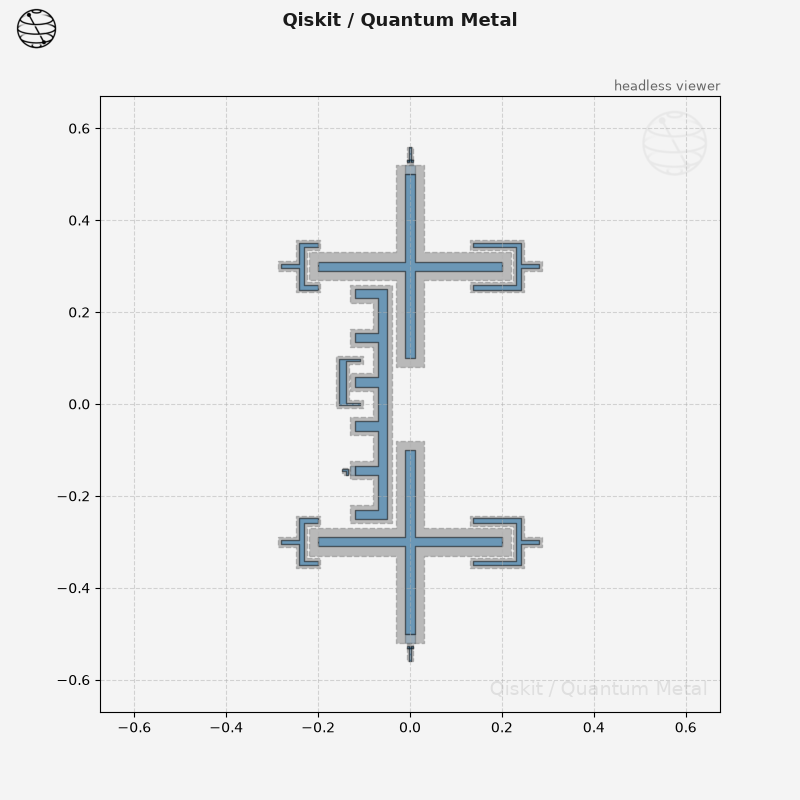

In [10]:
# Screenshot the canvas only as a .png formatted file.
gui.figure.savefig("shot.png")

from IPython.display import Image, display

_disp_ops = dict(width=500)
display(Image("shot.png", **_disp_ops))

In [11]:
# Closing the Qiskit Metal GUI
gui.main_window.close()